# Muffin or Chihuahua? A simple Neural Network study
Davide Gay

## INTRODUCTION

<figure>
  <img src="imgs/muffin_meme.jpg" width="200" alt="muffinvsdog">
  <figcaption> A muffin and a chihuaha can sometimes be hard to tell apart. (From https://www.pinterest.com/pin/481322278897185719/)</figcaption>
</figure>

The development of Neural Networks (NN) algorithms in the last few decades has provided powerful computer vision models to analyze and classify complex visual data at scale.

In this study, we use a number of architectures of increasing degrees of complexity to take on the task of recognizing images of dogs and muffins, and compare the results obtained to gain insight on NN behavior:
- Standard Feed Forward Neural Network (FFNN): a fully connected architecture trained directly on raw, flattened pixel inputs.
- Principal Component Analysis + FFNN (PCA+FFNN): dimensionality reduction via PCA applied prior to the FFNN to evaluate whether compressing high-dimensional feature spaces reduces noise and improves classification efficiency.
- 'Simple' Convolutional Neural Network model (CNN 1): A relatively lightweight convolutional model designed to capture local spatial hierarchies.
Using this architecture, we assess the impact of data augmentation and perform hyperparameter optimization.
- 'Complex' CNN (CNN 2): A deeper CNN architecture incorporating increased layer capacity and feature maps to test performance limits against the fine-grained visual features of the dataset.

In [313]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import pandas as pd
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import  Input, Rescaling, Conv2D, Dense, Flatten, Dropout, GlobalMaxPooling2D, MaxPooling2D, BatchNormalization
import hyperopt
#DATASET_URL = "https://www.kaggle.com/datasets/samuelcortinhas/muffin-vs-chihuahua-image-classification"
# NOTE: datasets were downloaded from Kaggle; alternatively, one can stream them from the URL above
TRAIN_DIR = './archive/train/'
TEST_DIR = './archive/test/'
BATCH_SIZE = 32
SEED = 123

#from IPython.display import Image

In [ ]:
def load_datasets(img_height, img_width):
    train_set = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR,
        #validation_split=0.2,
        seed=SEED,
        batch_size=32,
        labels='inferred',
        label_mode='int',
        shuffle=True,
        image_size=(img_height, img_width),
        #subset="training"
        )
    '''
    val_set = tf.keras.utils.image_dataset_from_directory(
        TRAIN_DIR,
        validation_split=0.2,
        seed=SEED,
        batch_size=32,
        labels='inferred',
        label_mode='int',
        image_size=(img_height, img_width),
        subset="validation")
    '''

    test_set = tf.keras.utils.image_dataset_from_directory(
        TEST_DIR,
        batch_size=32,
        seed=SEED,
        labels='inferred',
        label_mode='int',
        image_size=(img_height, img_width))

    return train_set, test_set

def build_augmentation(intensity=0.1):
    '''
    Data augmentation block
    '''
    return Sequential([
        tf.keras.layers.RandomFlip("horizontal"),
        tf.keras.layers.RandomRotation(intensity),
        tf.keras.layers.RandomZoom(intensity),
        tf.keras.layers.RandomContrast(intensity)
    ])

def plot_history(history, epochs):
    '''
    Plot history of model fit
    '''
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    epochs_range = range(epochs)

    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.plot(epochs_range, acc, label='Training Accuracy')
    plt.plot(epochs_range, val_acc, label='Validation Accuracy')
    plt.legend(loc='lower right')
    plt.title('Training and Test Accuracy')
    plt.grid(alpha=0.3)
    plt.xlim(left=0, right=epochs)
    plt.ylim( int(10*min(acc[0], val_acc[0]))/10 , 1.)
    plt.xlabel('Epochs')

    plt.subplot(1, 2, 2)
    plt.plot(epochs_range, loss, label='Training Loss')
    plt.plot(epochs_range, val_loss, label='Validation Loss')
    plt.legend(loc='upper right')
    plt.title('Training and Test Loss')
    plt.grid(alpha=0.3)
    plt.xlim(left=0, right=epochs)
    plt.ylim(0, (int(10*max(loss[0], val_loss[0]))+1)/10)
    plt.xlabel('Epochs')
    
    plt.show()

def history_to_csv(history, filename):
    hist = pd.DataFrame(history.history)
    hist.insert(0, 'epoch', history.epoch)
    hist.to_csv(filename, index=False)

def dataset_to_numpy(dataset):
    # TURN DATASET INTO NUMPY ARRAYS
    data_X = []
    data_labels = []
    
    for img, lab in dataset:
        data_X.append(img.numpy())
        data_labels.append(lab.numpy())
    
    return np.concatenate(data_X), np.concatenate(data_labels)

## THE DATASET

The dataset to be studied is comprised of 5919 images of muffins and dogs (mostly, but not limited to, chihuahuas) divided into a training set and a test set
and was obtained from https://www.kaggle.com/datasets/samuelcortinhas/muffin-vs-chihuahua-image-classification/code?datasetId=2733586&sortBy=voteCount

Interest in this seemingly peculiar dataset stems from humorous online claims about Machine Learning algorithms reportedly struggling to correctly label such images.

<figure>
  <img src="imgs/muffin-meme2.jpg" width="300" alt="MLdogs">
  <figcaption> "How to confuse machine learning" (from Kaggle website)</figcaption>
</figure>

While tackling this dataset is far from an impossible task for sufficiently complex and specialized Machine Learning models, it is true indeed that it requires learning fine spatial features, thus constituting an interesting "playground" to test the capabilities of different architectures.

As can be already seen from the images above, the eyes and noses of chihuahuas can be easily confused with dark spots on muffins (understandably chocolate or fruit). A human brain, from visual sensory data, can readily identify them in most cases using a combination of spatial organization (the respective position of the dogs' eyes and snout), fine details (e.g. shades on the dogs' faces or crumbles on muffins) and outside context (e.g. ears or paws for dogs, muffin wrappers or plates for muffins).

Found 4735 files belonging to 2 classes.
Found 1184 files belonging to 2 classes.


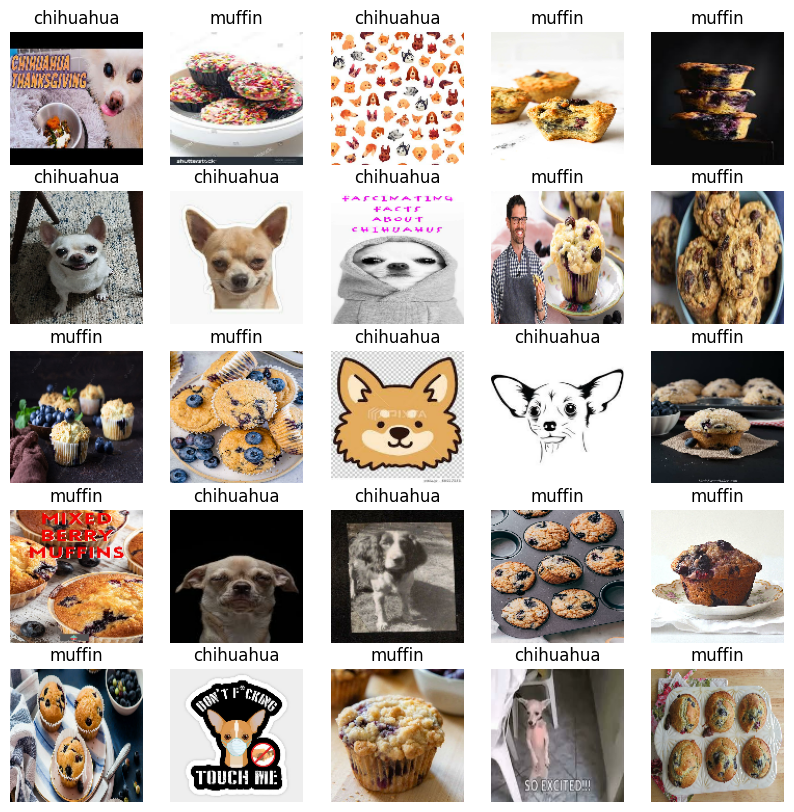

Image batch shape:  (32, 128, 128, 3)
Labels batch shape:  (32,)


In [103]:
HEIGHT = 128
WIDTH = 128
train_set, test_set = load_datasets(HEIGHT, WIDTH)

class_names = ['chihuahua', 'muffin']
num_classes = len(class_names)

plt.figure(figsize=(10, 10))
for images, labels in train_set.take(1):   # takes 1 batch !
    for i in range(25):
        plt.subplot(5, 5, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.show()

for image_batch, labels_batch in train_set:
    print("Image batch shape: ", image_batch.shape)
    print("Labels batch shape: ", labels_batch.shape)
    break

Here we have loaded the separate train dataset and test dataset (which is going to be used for validation) in batches of 32, and displayed 25 images from the training dataset. We can observe a certain variety among images of the same class. This should make the training more accurate and sensibly reduce the risk of overfitting.

## 1) FFNN
The idea of imitating the structure of the human brain in order to build algorithms capable of "learning", similarly to the human learning process, has long been entertained by researchers in various fields. The first attemp at formalizing such a concept dats back to 1947, when neurophysiologist Warren McCulloch and mathematician Walter Pitts introduced the concept of Artificial Neural Network [1], presented as a simplified computational model
of how biological neurons might work together in animal brains to perform complex
computations using propositional logic.

However, the first foundational work for the later development of Neural Networks was that of Frank Rosenblatt, who in 1958 introduced the Perceptron [2].
The artificial neuron involved in a Perceptron takes numbers as inputs
and output, and each input connection
is associated with a weight. The TLU computes a weighted sum of its inputs, then applies a step function to that sum and outputs the
result.
A single such neuron can be used for linear binary classification.
A Perceptron is composed of a single layer of neurons, with each neuron connected
to all the inputs. When all the neurons in a layer are connected to every neuron in the
previous layer, the layer is called a fully connected layer, or a
dense layer.
The Perceptron suffers from a few shortcomings, most notably the fact that it
is incapable of solving trivial problems such as the Exclusive OR (XOR).
Some of the limitations of Perceptrons can be eliminated by stacking
multiple Perceptrons, resulting in a Multilayer Perceptron (MLP).

<figure>
  <img src="imgs/perceptron.png" width="350" alt="perceptron">
  <figcaption>A Perceptron (from [3])</figcaption>
</figure>

The introduction of the Backpropagation algorithm in 1985 provided an efficient way to train MLPs by presenting a way to compute gradients to be used in Gradient Descent using an iterative rule [4].
In order for the algorithm to work properly the step function was changed to a sigmoid function, which has the necessary advantage of having a defined non-zero derivative everywhere. The sigmoid function is not the only option as activation function; others include the hyperbolic tangent and the Rectified Linear Unit function (ReLU).
Nowadays this type of architecture is mainly referred to as a Feed Forward Neural Network (FFNN).


### 1.1) FFNN Model
The basic model we work with in this section is composed of two dense layers of 64 units each, followed by a final sigmoid layer that provides the output.
The input data (single images) is first rescaled and flattened, thus obtaining an 1D array of size $128*128*3=49152$.

The model is then trained with the Adam algorithm (a variant of Stochastic Gradient Descent [5]) with learning rate set to $0.001$.
The loss function is a binary cross entropy:
$$L_{XE}(y_i,p_i)=-[y_i log(p_i) +(1-y_i)log(1-p_i)]$$
where $y_i$ is the true label and $p_i$ the probability obtained through the model. This loss is averaged over the dataset to obtain the total loss.

In [315]:
def build_NNmodel(IMG_HEIGHT, IMG_WIDTH, first_layer=128, second_layer=128, dropout=0.4, augmentation=True):
    '''
    Build NN model.
    '''
    return Sequential([
        Input( shape=(IMG_HEIGHT, IMG_WIDTH, 3) ),
        # data_augmentation:
        *( [build_augmentation()] if augmentation else []),
        # rescaling:
        Rescaling(1.0 / 255),
        Flatten(),

        Dense(first_layer, activation='relu'),
        Dropout(dropout),
        *( [Dense(second_layer, activation='relu'),
                ] if second_layer>0 else [] ),
        Dense(1,activation='sigmoid')
    ])

In [316]:
def fit_NNmodel(train_ds, val_ds, IMG_HEIGHT, IMG_WIDTH, parameters, augmentation=True,
                epochs=32, callbacks_f=None, summary=True, verbose=True):
    '''
    Build, compile, fit and evaluate model.
    Parameters should be dict containing: 'learning_rate', 'first_layer', 'second_layer', 'dropout'.
    Return model history.
    Useful for hyperopt
    '''
    # 1) BUILD MODEL
    model = build_NNmodel(IMG_HEIGHT, IMG_WIDTH,
                         int(parameters['first_layer']), int(parameters['second_layer']), parameters['dropout'],
                         augmentation=augmentation)
    # 2) COMPILE
    model.compile(loss='binary_crossentropy',
                  optimizer=tf.keras.optimizers.Adam(learning_rate=parameters['learning_rate']),
                  metrics=['accuracy'])
    if summary:(model.summary())
    # 3) FIT
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks_f, verbose=verbose)
    return model, history

Model: "sequential_154"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_99 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_48 (Flatten)            │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_284 (Dense)               │ (None, 64)             │     3,145,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_146 (Dropout)           │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_285 (Dense)               │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_286 (Dense)               │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,150,017 (12.02 MB)

 Trainable params: 3,150,017 (12.02 MB)

 Non-trainable params: 0 (0.00 B)

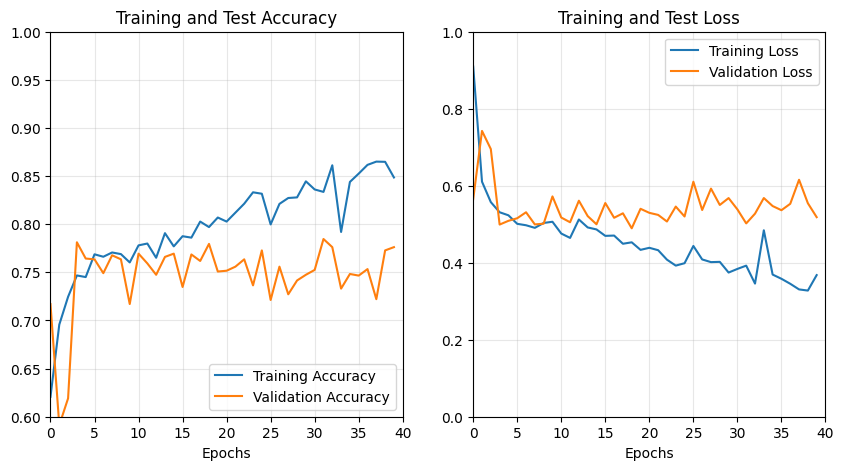

In [317]:
Param_NN1= {
    'learning_rate': 0.001,
    'first_layer': 64,
    'second_layer': 64,
    'dropout': 0.
}
EPOCHS=40

model_NN1 ,historyNN1= fit_NNmodel(train_set, test_set, HEIGHT, WIDTH, Param_NN1, augmentation=False,
                   epochs=EPOCHS, summary=True, verbose=False)
plot_history(historyNN1, epochs=EPOCHS)

This first architecture is not particularly suited for this task, and that is reflected in the mediocre results obtained, with the accuracy on the data set not reaching 80%. After a few epochs the validation accuracy ceases to improve and the validation loss slowly increases, while the training metrics keep improving, signaling overfitting. While the architecture is not large per se, the number of resulting parameters is very large due to the input data having a large dimensionality (the flattened images).

Greater sizes of Dense layers have been tried with no better outcome, instead simply making the training process more costly.

### Dropout
Between the two Dense layers we introduce a dropout layer: during each training step, a random subset of neurons is temporarily removed by setting their output to zero. 
Dropout helps in preventing overfitting by forcing the network to train different "thinned" sub-networks on every iteration, so that neurons cannot rely too heavily on their neighbors.

As can be noted from the resulting graph, even a relatively low dropout rate of 0.1 surely prevents overfitting, but prevents the model from learning effectively as well, with slightly worse results.

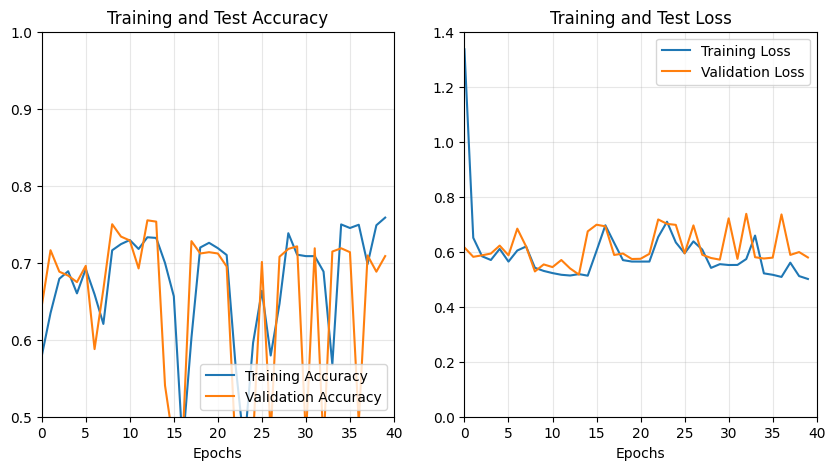

In [311]:
Param_NN1= {
    'learning_rate': 0.001,
    'first_layer': 64,
    'second_layer': 64,
    'dropout': 0.1
}
EPOCHS=40

model_NN1 ,historyNN1= fit_NNmodel(train_set, test_set, HEIGHT, WIDTH, Param_NN1, augmentation=False,
                   epochs=EPOCHS, summary=False, verbose=False)
plot_history(historyNN1, epochs=EPOCHS)

### Data augmentation
Here we introduce a data augmentation layer. This consists of a set of transformations
(namely: horizontal flips, rotations, zoom, contrast) applied to the input data before rescaling and flattening. The goal of data augmentation is to artificially increase the diversity in the training dataset, helping the model generalize better.
Understandably, we expect the results to be unaffected at this stage, since the model is far too primitive to learn fine spatial features and therefore benefit from augmentation. Data augmentation will however be impactful when working with CNNs.

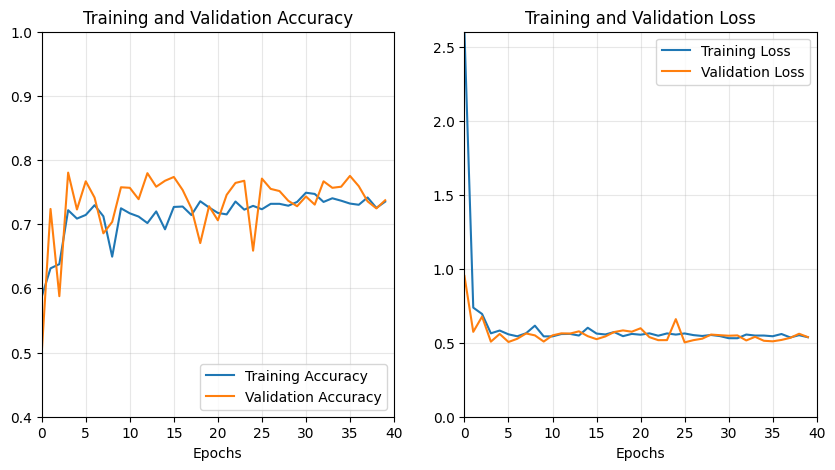

In [ ]:
model_NN1_aug ,historyNN1_aug= fit_NNmodel(train_set, test_set, HEIGHT, WIDTH, Param_NN1, augmentation=True,
                   epochs=EPOCHS, summary=False, verbose=False)
plot_history(historyNN1_aug, epochs=EPOCHS)

### 1.2) PCA

Principal Component Analysis (PCA) is a dimensionality reduction method.
It was introduced in 1901 by Pearson as an analogue of the principal axis theorem in mechanics [6].
Indeed, PCA can be thought of as fitting a p-dimensional ellipsoid to the data, where each axis of the ellipsoid represents a principal component. If some axis of the ellipsoid is small, then the variance along that axis is also small.

More precisely, using Singular Value Decomposition, the covariance matrix of the centered distribution of the data is diagonalized; the eigenvectors thus obtained (called Principal Components) constitute a orthogonal basis and the corresponding eigenvectors measure the variance of the dataset along the direction identified by the corresponding eigenvector. An orthogonal linear transformation matrix is thereby obtained that transforms the data to a new coordinate system identified by the Principal Components. The Principal Components are conventionally named in order starting from the one with highest variance.

It can be shown that the subspace of dimension $p<P$ along which the projection of the distribution $X$ in dimension $P$ best approximates the original distribution is given by the span of the $p$ Principal Components corresponding to the highest variance (i.e. the first $p$ Principal Components, according to the order described above).

<figure>
  <img src="imgs/pca.png" width="350" alt="pca">
  <figcaption>Principal Components of a 2-dimensional dataset (from [3])</figcaption>
</figure>

We integrate PCA in our FFNN model:
1) using sklearn's PCA method, we perform a PCA fit on the flattened dataset. That is, we extract the mean of the dataset, which can be subtracted to the dataset to translate it to be centered at the origin, and most importantly the projection matrix that projects the dataset on the subspace spanned by the PC components with the highest variance. This matrix shall have dimension ($n_{comp}$, $N$), where $n_{comp}$ is the desired dimensionality of the subspace (here $n_{comp}=100$) and $N$ is the original dimension of the feature spce ($N=128*128*3=49152$).
2) We introduce a PCA layer to the model pipeline. This layer will project the (flattened) images onto the PCA subspace, after having centered them in the origin.
3) The rest of the pipeline is the same as described before.

In [122]:
from sklearn.decomposition import PCA

# Step A: Normalize to [0, 1] and flatten images for sklearn PCA fit
train_X, train_labels = dataset_to_numpy(train_set)
num_train_samples = train_X.shape[0]
X_train_flat = (train_X / 255.0).reshape(num_train_samples, -1)

# Step B: Fit PCA to reduce dimensions (e.g., to 50 components)
n_components = 100
pca = PCA(n_components=n_components)
pca.fit(X_train_flat)

# Extract fitted components (shape: [n_components, original_features]) and mean vector
pca_components = pca.components_.T.astype("float32")  # Transpose to shape: (original_features, n_components)
pca_mean = pca.mean_.astype("float32")

In [ ]:
class PCALayer(layers.Layer):
    '''
    Custom PCA Layer:
    applies previously learned transormation (projects to subspace)
    '''
    def __init__(self, components, mean, **kwargs):
        super().__init__(**kwargs)
        # Store components and mean as non-trainable TensorFlow constants
        self.components = tf.constant(components, dtype=tf.float32)
        self.mean = tf.constant(mean, dtype=tf.float32)

    def call(self, inputs):
        # Subtract mean vector and project onto principal components: (X - mean) @ W
        centered_inputs = inputs - self.mean
        return tf.matmul(centered_inputs, self.components)

def build_PCAmodel(IMG_HEIGHT, IMG_WIDTH, first_layer=128, second_layer=128, dropout=0.4, augmentation=True):
    '''
    Build NN model with PCA layer.
    '''
    return Sequential([
        Input( shape=(IMG_HEIGHT, IMG_WIDTH, 3) ),
        # - Data augmentation:
        *( [build_augmentation()] if augmentation else []),
        # - Rescaling
        Rescaling(1.0 / 255),
        Flatten(),
        # - PCA Layer
        PCALayer(components=pca_components, mean=pca_mean, name="pca_projection"),

        Dense(first_layer, activation='relu'),
        Dropout(dropout),
        Dense(second_layer, activation='relu'), 
        Dropout(dropout),
        Dense(1,activation='sigmoid')
    ])

def fit_PCAmodel(train_ds, val_ds, IMG_HEIGHT, IMG_WIDTH, parameters, augmentation=True,
                epochs=32, callbacks_f=None, summary=True, verbose=True):
    '''
    Build, compile, fit and evaluate model.
    Parameters should be dict containing: 'learning_rate', 'first_layer', 'second_layer', 'dropout'.
    Return model history.
    Useful for hyperopt
    '''
    # 1) BUILD MODEL
    model = build_PCAmodel(IMG_HEIGHT, IMG_WIDTH,
                         int(parameters['first_layer']), int(parameters['second_layer']), parameters['dropout'],
                         augmentation=augmentation)
    # 2) COMPILE
    model.compile(loss='binary_crossentropy',
                  optimizer=tf.keras.optimizers.Adam(learning_rate=parameters['learning_rate']),
                  metrics=['accuracy'])
    if summary:(model.summary())
    # 3) FIT
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks_f, verbose=verbose)
    return model, history

Model: "sequential_55"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_54 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_41 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_37 (Flatten)            │ (None, 49152)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pca_projection (PCALayer)       │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_110 (Dense)               │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_39 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_111 (Dense)               │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_112 (Dense)               │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,905 (359.00 KB)

 Trainable params: 91,905 (359.00 KB)

 Non-trainable params: 0 (0.00 B)

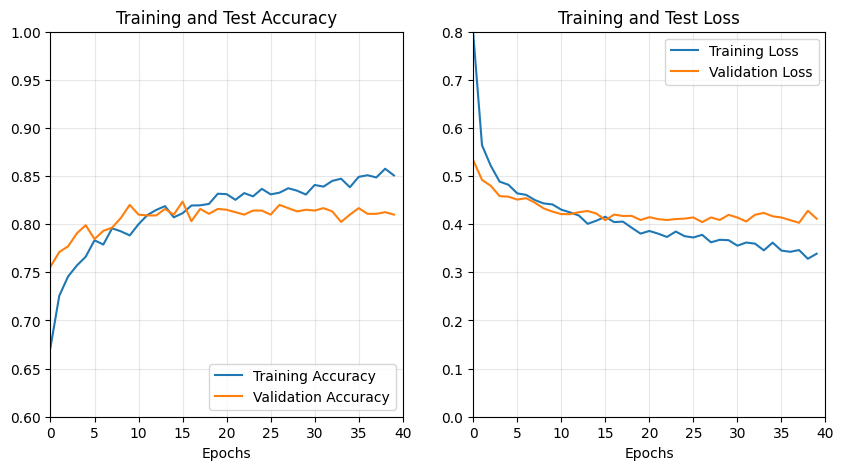

In [138]:
Param= {
    'learning_rate': 0.001,
    'first_layer': 256,
    'second_layer': 256,
    'dropout': 0.2
}
EPOCHS=40

model_PCA ,historyPCA= fit_PCAmodel(train_set, test_set, HEIGHT, WIDTH, Param, augmentation=True,
                   epochs=EPOCHS, summary=True, verbose=False)
plot_history(historyPCA, epochs=EPOCHS)

With the PCA transformation reducing the dimension of the design matrix (to 100 components in this case), the model tends to overfit quite easily. To limit this occurence, we employ dropout layers after each Dense layer and apply data augmentation on the images before flattening.

However, the PCA+FFNN model appears to cap at around 82% accuracy regardless of PCA components, architecture or combinations of hyperparameters. More complex models, as those described in the following sections, are required to reach satisfactory results.

## 2) CNN

The concept of Convolutional Neural Network (CNN) was first introduced in the work of Fukushima in 1980
as a neural network model for visual pattern recognition [7].
It was based on the hierarchy model of the visual
nervous system of vertebrates proposed by Hubel and Wiesel [8], where individual neurons respond to restricted regions of the visual field and local features extracted in lower stages are gradually integrated into more global features.

Foundational works in the following decades ([9],[10] among others) laid the ground for the development and formalization of the various features that define CNNs and the study of the impact of these features on the effectiveness of the model.

What follows is a brief overview of the key ingredients of a CNN.

### I) CONVOLUTION
Convolutional layers are the fundamental building block of CNNs. The idea is that
neurons in a convolutional layer are not connected to every single pixel in the input image
(as in a standard FFNN), but only to pixels in their receptive fields.
This architecture allows the network to concentrate on small low-level features in the
first hidden layer, then assemble them into larger higher-level features in the next
hidden layers.

In order for a layer to have the same height and width as the previous layer, it is com mon to add zeros around the inputs,
in a procedure known as zero padding.

<figure>
  <img src="imgs/convo.png" width="450" alt="convolutional_layers">
  <figcaption>Visualization of a convolutional layer (from [3])</figcaption>
</figure>

### II) FILTERS
Convolutional layers apply filters to extract meaningful features like edges, textures, and patterns.

Filters (or convolution kernels) are small, learnable matrices of weights that slide across an input image to detect specific visual pattern.
As a filter convolves across the image, it performs element-wise multiplication and sums the results, producing a two-dimensional grid called a feature map.
Each feature map highlights where and how strongly its corresponding filter detected its target feature within the input.

<figure>
  <img src="imgs/convofilters.png" width="450" alt="Convolution_filters">
  <figcaption>Convolutional layers with feature maps (from [3])</figcaption>
</figure>

### III) POOLING
The goal of a pooling layer is to subsample the input image in order to
reduce the computational load and the number of parameters, limiting the risk of overfitting.
A pooling neuron aggregates the inputs using a function such as the max or mean.

<figure>
  <img src="imgs/pooling.png" width="400" alt="Pooling">
  <figcaption>Max pooling layer with 2×2 pooling kernel, stride 2, no padding (from [3])</figcaption>
</figure>

### 2.1) FIRST CNN MODEL

We start by implementing a relative simple and flexible CNN architecture. Using this first model we can understand the impact of the various hyperparameters on the results before moving on to a more elaborate model.
This model features:
- a data augmentation layer (more on this later)
- a rescaling layer
- 3 convolutional layers with increasing number of filters, each followed by a max pooling layer
- a global average pooling layer to return a flat array
- a double Dense FFNN layer similar to the one implemented in the previous section, including dropout and final sigmoid layer.

In [ ]:
def build_model_CNN1(IMG_HEIGHT, IMG_WIDTH, first_layer=128, second_layer=128, dropout=0.4, augmentation=True):
    '''
    Build CNN model.
    '''
    return Sequential([
        Input( shape=(IMG_HEIGHT, IMG_WIDTH, 3) ),
        # data_augmentation:
        *( [build_augmentation()] if augmentation else []),
        # rescaling:
        Rescaling(1.0 / 255),

        Conv2D(32, kernel_size=(3, 3), padding='same'),
        tf.keras.layers.Activation('relu'),
        MaxPooling2D(pool_size=(2, 2)),
        
        Conv2D(64, kernel_size=(3, 3), padding='same'),
        tf.keras.layers.Activation('relu'),
        MaxPooling2D(pool_size=(2, 2)),
        
        Conv2D(128, kernel_size=(3, 3), padding='same'),
        tf.keras.layers.Activation('relu'),
        MaxPooling2D(pool_size=(2, 2)),
        
        # Get flat array:
        tf.keras.layers.GlobalAveragePooling2D(),
        Dense(first_layer, activation='relu'),
        Dropout(dropout),
        *( [Dense(second_layer, activation='relu'), 
                Dropout(dropout)] if second_layer>0 else [] ),
        # final layer
        Dense(1,activation='sigmoid')
    ])

def fit_model_CNN1(train_ds, val_ds, IMG_HEIGHT, IMG_WIDTH, parameters, augmentation=True,
                epochs=32, callbacks_f=None, summary=True, verbose=True):
    '''
    Build, compile, fit and evaluate model.
    Parameters should be dict containing: 'learning_rate', 'first_layer', 'second_layer', 'dropout'.
    Return model history.
    Useful for hyperopt
    '''
    # 1) BUILD MODEL
    model = build_model_CNN1(IMG_HEIGHT, IMG_WIDTH,
                         int(parameters['first_layer']), int(parameters['second_layer']), parameters['dropout'],
                         augmentation=augmentation)
    # 2) COMPILE
    model.compile(loss='binary_crossentropy',
                  optimizer=tf.keras.optimizers.Adam(learning_rate=parameters['learning_rate']),
                  metrics=['accuracy'])
    if summary:(model.summary())
    # 3) FIT
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks_f, verbose=verbose)
    return model, history

Model: "sequential_59"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_58 (Sequential)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_43 (Rescaling)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_116 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_43 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_117 (Dense)               │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_44 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_118 (Dense)               │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 126,401 (493.75 KB)

 Trainable params: 126,401 (493.75 KB)

 Non-trainable params: 0 (0.00 B)

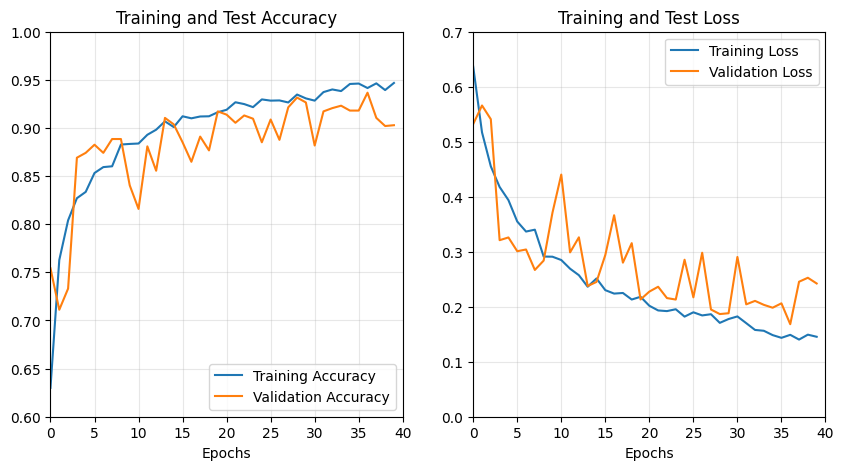

"\nwith open('./histories/history1_001_128_128_4.json', 'w') as f:\n    json.dump(history1.history['val_accuracy'], f)\n"

In [ ]:
Param= {
    'learning_rate': 0.001,
    'first_layer': 128,
    'second_layer': 128,
    'dropout': 0.4
}
EPOCHS=40

model_CNN1, history_CNN1= fit_model_CNN1(train_set, test_set, HEIGHT, WIDTH, Param, augmentation=True,
                   epochs=EPOCHS, summary=True, verbose=False)
plot_history(history_CNN1, epochs=EPOCHS)

As we can clearly see, results are considerably better than those of the FFNN model. The validation accuracy touches 94% while the loss goes below 0.2. We are interested to see if by tuning the hyperparameters we can obtain even better results.

### HYPERPARAMETER OPTIMIZATION
To tune the hyperparameters in order to achieve the best performance, several algorithms can be utilised. The simplest and often most expensive ones are Grid Search and Random Search algorithms.
Here we use a Tree-Structured Parzen Estimator (TPE) [11], which is a sequential model-based optimization algorithm (SMBO).
A SMBO's aim is to minimize a cost function $f$, whose evaluation is generally expensive, by working with a surrogate function $\bar{f}$ which is easier to compute and is used to propose a new search point.

In a TPE, the surrogate model
is a probabilistic model p(y|x), where y indicates the loss function value to be optimized and x the set of hyperparameters,
which chooses the next trial point by optimizing the Expected
Improvement criterion:
$$ EI_{y*}(x) = \int_{-\infty}^{+\infty} max(y-y*, 0) p(y|x)dy $$
It measures how much the loss function is expected to be lower than a threshold value $y*$,
chosen so that $p(y<y*) = \gamma$ where $\gamma$ is a parameter of the algorithm.
The probability distribution is obtained with Bayes Theorem: $p(y|x)=p(x|y)p(y)/p(x)$, where
$p(x|y)=l(x)$ if $y<y*$, i.e. the score is better than the threshold; $p(x|y)=g(x)$ otherwise.
These probability distributions are estimated by using the trials $x_i$ at each step of the algorithm.
The Expected Improvement has a closed form and is proportional to $\frac{l(x)}{g(x)}$; it is used to select the next set of hyperparameters in the attempt to optimize the score.

Here we first define the function to be optimized as the loss on the test set, then the search space:

In [234]:
def hyper_func_1(params):
        model, history = fit_model_CNN1(train_set, val_set, HEIGHT, WIDTH, params, epochs=60, summary=False)
        test_acc = history.history['val_accuracy'][-1]
        test_loss = history.history['val_loss'][-1]
        
        return {'loss': test_loss, 'status': hyperopt.STATUS_OK}

In [ ]:
layers=[64,128,256]
dropouts=np.arange(0., 0.6, 0.1)

# Defining the search space:
search_space_1 = {
        'first_layer': hyperopt.hp.choice('first_layer', layers),
        'second_layer': hyperopt.hp.choice('second_layer', layers),
        'dropout': hyperopt.hp.choice('dropout', dropouts),
        'learning_rate': hyperopt.hp.loguniform('learning_rate', np.log(1e-5), np.log(1e-2)) #hyperopt.hp.loguniform('learning_rate', -10, 0)
    }

trials_1 = hyperopt.Trials()
best_1 = hyperopt.fmin(hyper_func_1, search_space_1, algo=hyperopt.tpe.suggest, max_evals=8, trials=trials_1)

# NOTE: the output of this cell has been cut since it was very extensive.

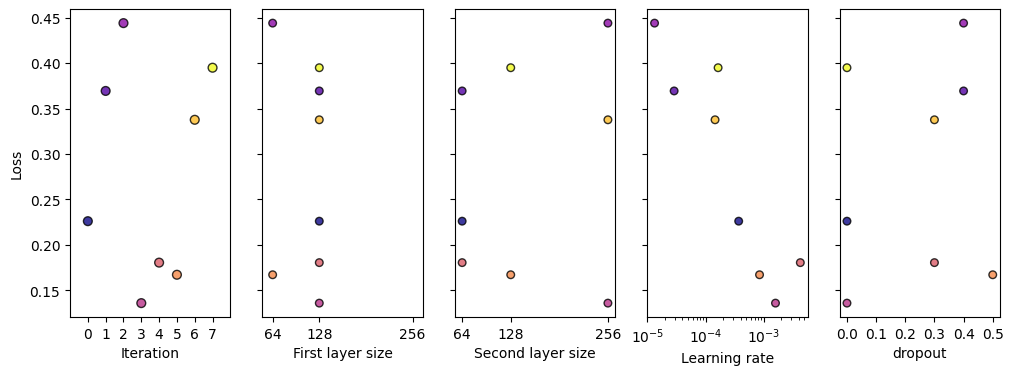

BEST PARAMETERS:
dropout : 0.0
first_layer : 128
learning_rate : 0.001600242928872531
second_layer : 256


In [325]:
#layers=[64,128,256]
_, (ax1, ax2, ax3, ax4, ax5) = plt.subplots(1, 5, figsize=(12, 4), sharey=True)
iteration_numbers = list(range(len(trials_1.trials)))

xs = [t['tid'] for t in trials_1.trials]
ys = [t['result']['loss'] for t in trials_1.trials]
ax1.set_xlim(xs[0]-1, xs[-1]+1)
ax1.scatter(xs, ys, s=40, c=iteration_numbers, cmap='plasma', edgecolors='k', alpha=0.8)
ax1.set_xlabel('Iteration')
#ax5.set_xlim(-0.5,8)
ax1.set_xticks([0,1,2,3,4,5,6,7])
ax1.set_ylabel('Loss')

xs = [t['misc']['vals']['first_layer'] for t in trials_1.trials]
ys = [t['result']['loss'] for t in trials_1.trials]
ax2.scatter([layers[i[0]] for i in xs], ys, s=30, c=iteration_numbers, cmap='plasma', edgecolors='k', alpha=0.8)
ax2.set_xlabel('First layer size')
ax2.set_xticks(layers)
ax2.set_xlim(50,270)

xs = [t['misc']['vals']['second_layer'] for t in trials_1.trials]
ys = [t['result']['loss'] for t in trials_1.trials]
ax3.scatter([layers[i[0]] for i in xs], ys, s=30, c=iteration_numbers, cmap='plasma', edgecolors='k', alpha=0.8)
ax3.set_xlabel('Second layer size')
#ax3.set_ylabel('Loss')
ax3.set_xticks(layers)
ax2.set_xlim(50,270)

xs = [t['misc']['vals']['learning_rate'] for t in trials_1.trials]
ys = [t['result']['loss'] for t in trials_1.trials]
ax4.semilogx()
ax4.scatter(xs, ys, s=30, c=iteration_numbers, cmap='plasma', edgecolors='k', alpha=0.8)
ax4.set_xlabel('Learning rate')
#ax5.set_ylabel('Loss')

xs = [t['misc']['vals']['dropout'] for t in trials_1.trials]
ys = [t['result']['loss'] for t in trials_1.trials]
ax5.scatter([dropouts[i[0]] for i in xs], ys, s=30, c=iteration_numbers, cmap='plasma', edgecolors='k', alpha=0.8)
ax5.set_xlabel('dropout')
#ax4.set_ylabel('Loss')
ax5.set_xticks(dropouts)

plt.show()

#print(hyperopt.space_eval(search_space_1, best_1))
print('BEST PARAMETERS:')
for parameter in hyperopt.space_eval(search_space_1, best_1):
    print (parameter, ':', hyperopt.space_eval(search_space_1, best_1)[parameter])

The graph above shows the mapped points of the search space through 8 iterations of the TPE algorithm with the corresponding loss. The color map indicates the iteration. It is interesting to note that the best value obtained for the dropout rate was 0 (though there does not appear to be a trend that indicates low dropout rates are generally preferrable).

Ideally, more than 8 iterations would be needed to properly map the search space. Such a task, however, exceeds the resources (computational resources and real world time) presently available for this study.

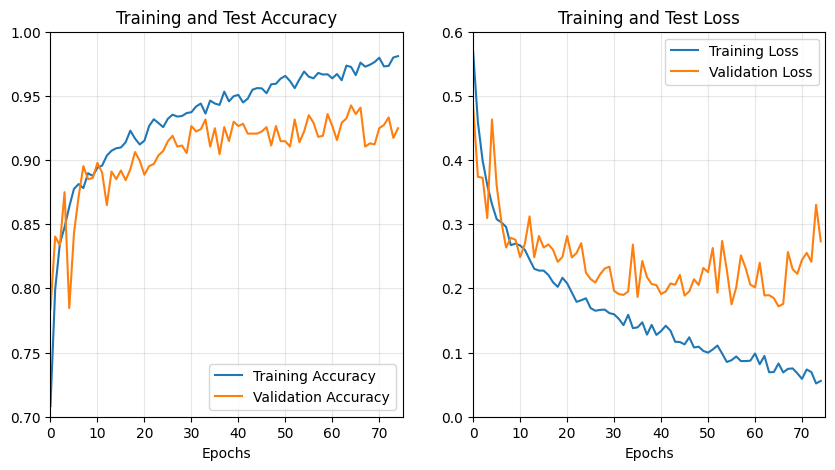

Test loss: 0.18486453592777252
Test accuracy: 0.9425675868988037


In [ ]:
best_Param_1= hyperopt.space_eval(search_space_1, best_1)
EPOCHS=75

# CALLBACKS
save_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath='./histories/model1_best.keras',
    monitor='val_accuracy', mode='max',
    save_best_only=True, verbose=0)

# TRAIN
model_CNN1best, history_CNN1best= fit_model_CNN1(train_set, test_set, HEIGHT, WIDTH, best_Param_1, augmentation=True,
                   epochs=EPOCHS, summary=False, verbose=False, callbacks_f=save_checkpoint)
plot_history(history_CNN1best, epochs=EPOCHS)

# SAVE HISTORY
history_to_csv(history_CNN1best, './histories/history_CNN1best.csv')

# EVALUATE BEST MODEL
model1_best = tf.keras.models.load_model('./histories/model1_best.keras')
score1_best = model1_best.evaluate(test_set, verbose=False)
print('Test loss:', score1_best[0])
print('Test accuracy:', score1_best[1])
# NOTE: saved models are not provided within the current directory as the size of those files is quite large.

This "optimized" model barely surpasses the starting model (see the validation loss). We can also note that near epoch 70 the loss starts to increase, signaling overfitting.

### 2.2) No Augmentation
We assess the impact of data augmentation on the CNN by training the same model with the same set of hyperparameters, this time excluding the augmentation layer.

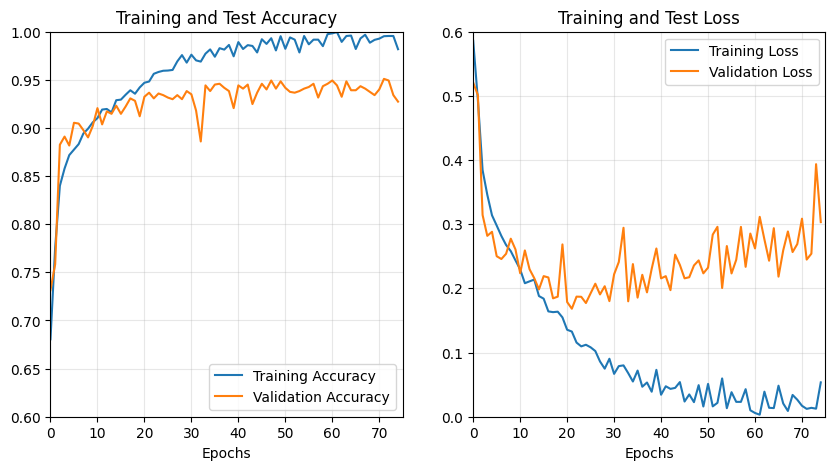

Test loss: 0.24489521980285645
Test accuracy: 0.9510135054588318


In [ ]:
# CALLBACKS
save_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath='./histories/model1_best_noaug.keras',
    monitor='val_accuracy', mode='max',
    save_best_only=True, verbose=0)

# TRAIN
model_CNN1best_noaug, history_CNN1best_noaug= fit_model_CNN1(train_set, test_set, HEIGHT, WIDTH, best_Param_1, augmentation=False,
                   epochs=75, summary=False, verbose=False,
                   callbacks_f=save_checkpoint)
plot_history(history_CNN1best_noaug, epochs=75)

# SAVE HISTORY
history_to_csv(history_CNN1best_noaug, './histories/history_CNN1best_noaug.csv')

# EVALUATE BEST MODEL
model1_best_noaug = tf.keras.models.load_model('./histories/model1_best_noaug.keras')
score1_best_noaug = model1_best_noaug.evaluate(test_set, verbose=False)
print('Test loss:', score1_best_noaug[0])
print('Test accuracy:', score1_best_noaug[1])
# NOTE: saved models are not provided within the current directory as the size of those files is quite large.

Perhaps surprisingly, the accuracy achieved without implementing data augmentation is slightly higher. Is it important to note, however, that while the accuracy reaches a plateau between 30 and 40 epochs, the loss progressively increases. This indicates that the model is in fact becoming "more confident" in its mistakes.

All things considered, we have assessed that data augmentation appears to help in preventing overfitting, at the cost of a slightly worse accuracy for this model. We can expect that with a more complex CNN model data augmentation can be even more useful in preventing overfitting and letting the model learn more effectively over many epochs.

### 2.3) DEEPER CNN

Lastly, we design a deeper CNN architecture, as seen in https://www.kaggle.com/code/jakubwalczykowski/chihuahua-vs-muffin-round1.
We highlight the main differences/improvements from the previous architecture:
- it takes as input 256x256 images, instead of 128x128, to potentially study even more fine details;
- it employs a double convolutional layer before each Max Pooling 2D Layer;
- it adopts Global Max Pooling instead of Global Average Pooling to get flattened data;
- it introduces Batch Normalization after each Convolutional layer;
- the FFNN layers at the end are larger (512 and 1024).

Batch Normalization is a normalization technique used to make training faster and more stable by adjusting the inputs to each layer, re-centering them around zero and re-scaling them to a standard size [12]. 

In [249]:
# load 256x256 images
HEIGHT_2= 256
WIDTH_2= 256
train_set_256, test_set_256 = load_datasets(HEIGHT_2, WIDTH_2)

Found 4735 files belonging to 2 classes.
Found 1184 files belonging to 2 classes.


In [ ]:
# Credits: Jakub Walczykowski, https://www.kaggle.com/code/jakubwalczykowski/chihuahua-vs-muffin-round1
model_CNN2 = Sequential([
    tf.keras.layers.Input( shape=(HEIGHT_2, WIDTH_2, 3) ),
    build_augmentation(),
    tf.keras.layers.Rescaling(1.0 / 255),
    Conv2D(32,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    Conv2D(32,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Conv2D(64,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    Conv2D(64,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    Conv2D(128,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    Conv2D(128,(3,3),activation='relu',padding='same'),
    BatchNormalization(),
    MaxPooling2D((2,2)),
    GlobalMaxPooling2D(),
    Flatten(),
    Dense(512,activation='relu'),
    Dropout(0.2),
    Dense(1024,activation='relu'),
    Dropout(0.2),
    Dense(1,activation='sigmoid')
])

model_CNN2.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model_CNN2.summary()

Model: "sequential_144"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_143 (Sequential)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_89 (Rescaling)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_141 (Conv2D)             │ (None, 256, 256, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_18          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_142 (Conv2D)             │ (None, 256, 256, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_19          │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_141               │ (None, 128, 128, 32)   │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_143 (Conv2D)             │ (None, 128, 128, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_144 (Conv2D)             │ (None, 128, 128, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_142               │ (None, 64, 64, 64)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_145 (Conv2D)             │ (None, 64, 64, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_146 (Conv2D)             │ (None, 64, 64, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 64, 64, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_143               │ (None, 32, 32, 128)    │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling2d            │ (None, 128)            │             0 │
│ (GlobalMaxPooling2D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_38 (Flatten)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_254 (Dense)               │ (None, 512)            │        66,04

 Total params: 881,185 (3.36 MB)

 Trainable params: 880,289 (3.36 MB)

 Non-trainable params: 896 (3.50 KB)

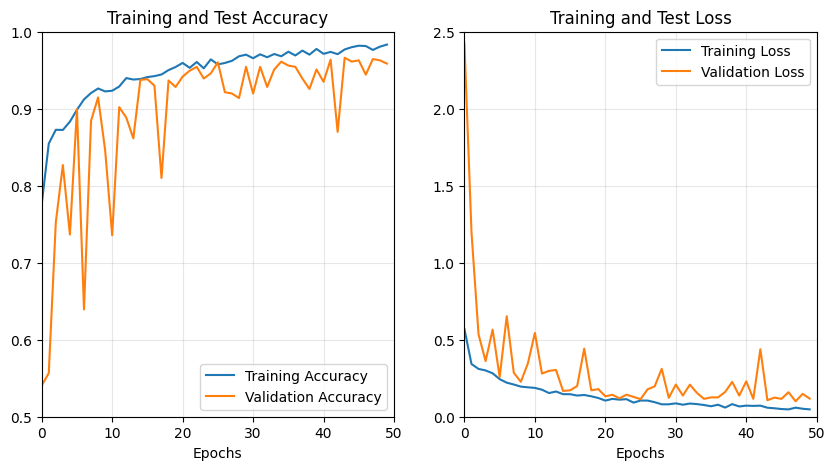

Test loss: 0.23366360366344452
Test accuracy: 0.9189189076423645


In [ ]:
# CALLBACKS
save_checkpoint = tf.keras.callbacks.ModelCheckpoint(filepath='./histories/model2.keras',
    monitor='val_accuracy', mode='max',
    save_best_only=True, verbose=0)

# TRAIN
epochs=50
history_CNN2 = model_CNN2.fit(
  train_set_256,
  validation_data=test_set_256,
  epochs=epochs,
  callbacks=[save_checkpoint],
  verbose=0
)
plot_history(history_CNN2, epochs=epochs)

# SAVE HISTORY
history_to_csv(history_CNN2, './histories/history_CNN2.csv')

In [ ]:
# EVALUATE MODEL
model2 = tf.keras.models.load_model('./histories/model2.keras')
score2 = model2.evaluate(test_set_256, verbose=False)
print('Test loss:', score2[0])
print('Test accuracy:', score2[1])
# NOTE: saved models are not provided within the current directory as the size of those files is quite large.

Test loss: 0.10696040093898773
Test accuracy: 0.9662162065505981


We can observe that the model reaches a great level of accuracy and loss. Accounting for the remaining $\sim$ 3.5% inaccurate predictions would not be an easy task, and would most likely require the use of massive architectures with pre-trained weights (e.g. EfficientNet [13] or others).

We can have an idea of the type of errors made by the model by computing the confusion matrix and by having a look at some of the misclassified images directly.

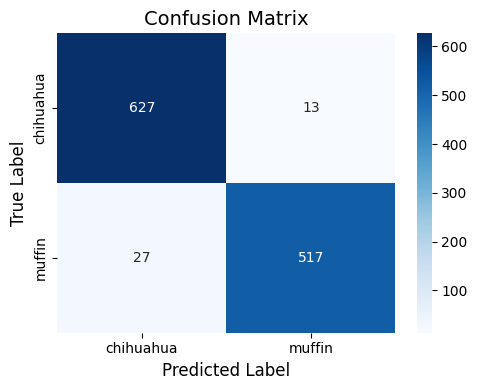

Total misclassified images found: 40


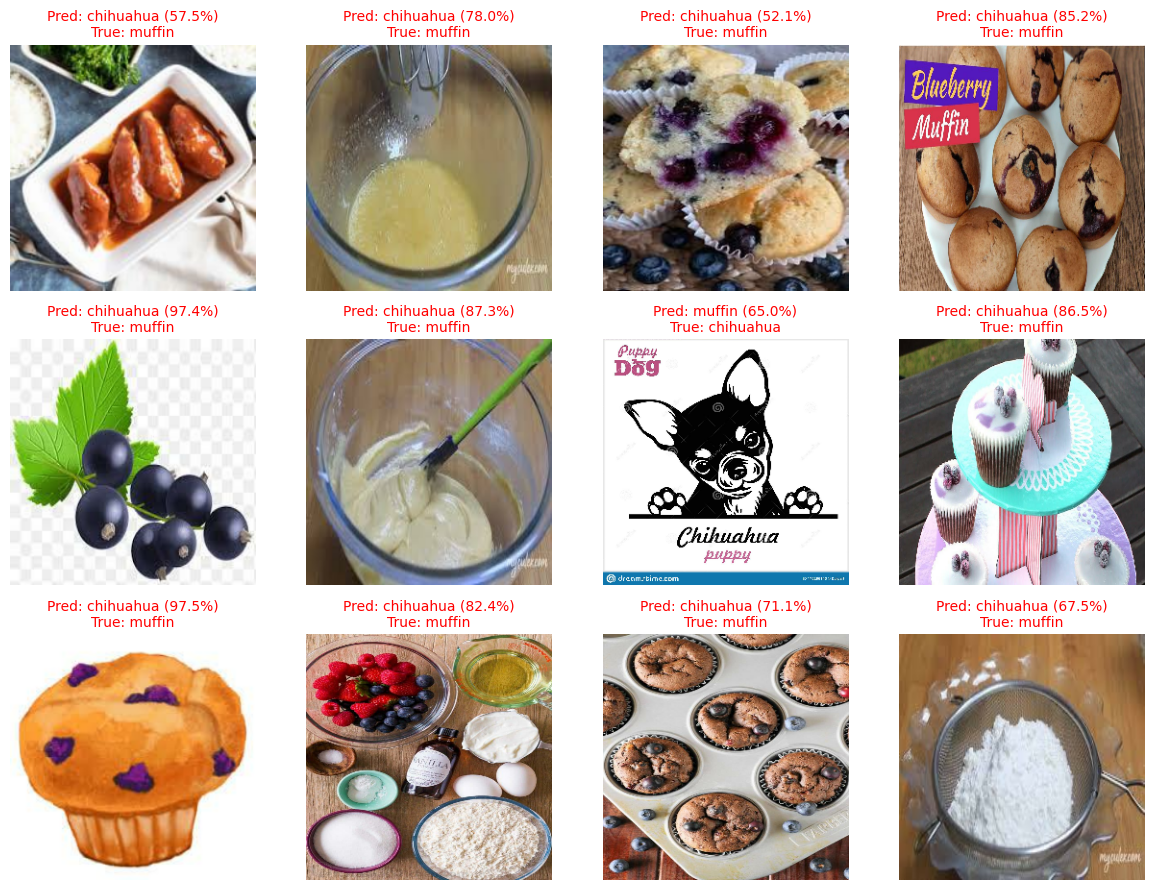

In [ ]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

#class_names = test_set_256.class_names
y_true = []
y_pred = []

misclassified_images = []
misclassified_labels = []
predicted_labels = []
confidences = []

for images, labels in test_set_256: # in batch
    # Predict probabilities
    preds = model2.predict(images, verbose=0)
    # Sigmoid prediction (binary output: shape=[batch_size, 1])
    batch_preds = (preds > 0.5).astype(int).flatten()
    raw_probs = preds.flatten()

    batch_y = labels.numpy().flatten()

    # Find errors
    error_indices = [i for i, pred in enumerate(batch_preds) if pred != batch_y[i]]
    for err_idx in error_indices:
        misclassified_images.append(images[err_idx].numpy())
        misclassified_labels.append(batch_y[err_idx])
        predicted_labels.append(batch_preds[err_idx])
        
        prob = raw_probs[err_idx]
        conf = prob if batch_preds[err_idx] == 1 else (1.0 - prob)
        confidences.append(conf)

    y_pred.extend(batch_preds)
    y_true.extend(batch_y)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# --------------------------------------------- #
# Confusion Matrix:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Confusion Matrix', fontsize=14)
plt.tight_layout()
plt.show()

# --------------------------------------------- #
# Plot misclassified images:
print(f"Total misclassified images found: {len(misclassified_images)}")
num_to_plot = min(12, len(misclassified_images))
fig, axes = plt.subplots(3, 4, figsize=(12, 9))
axes = axes.flatten()
for i in range(num_to_plot):
    img = misclassified_images[i]
    if img.max() <= 1.0:
        img = (img * 255.0).astype("uint8")
    else:
        img = img.astype("uint8")
    pred_name = class_names[predicted_labels[i]]
    true_name = class_names[misclassified_labels[i]]
    conf = confidences[i]
    axes[i].imshow(img)
    axes[i].set_title(
        f"Pred: {pred_name} ({conf:.1%})\nTrue: {true_name}", 
        color="red", 
        fontsize=10
    )
    axes[i].axis("off")
# Hide unused subplots
for j in range(num_to_plot, len(axes)):
    axes[j].axis("off")
plt.tight_layout()
plt.show()

We can see that a good fraction of the misclassified images are muffins classified as chihuahuas. Among the images depicted above we observe a recurring theme inside this group: baking ingredients, that do not resemble a muffin visually. It seems reasonable to expect a NN not to be able to consistently label them correctly.

### CONCLUSIONS
We have tested the capabilities of a few different NN architectures (FFNN, PCA+FFNN, CNN) and investigated the impact of features and hyperparameters. The FFNN model has expectedly performed rather poorly, since it cannot learn spatial patterns by construction. Adding PCA to this model slightly improves the result, but it still settles barely above 80% validation accuracy. The CNN models on the other hand have performed satisfiyngly well: a first lightweight model has been used to test the role of data augmentation and to perform hyperparameter optimization and has reached around 95% validation accuracy; a second, deeper model has reached 96.6% validation accuracy and 0.11% validation loss.
From these results, and from the misclassified images by this last model, we can conclude that better performances most likely require to abandon custom architectures such as the ones built in this study in favor of robust especially designed models employing pre-trained weights.

## REFERENCES

1) McCulloch W., Pitts W.,
*A Logical Calculus of Ideas Immanent in
Nervous Activity*,
(1943)
2) Rosenblatt F.,
*The perceptron: A probabilistic model for information storage and organization in the brain*,
Psychological Review, 65(6), 386–408
(1958)
3) Géron A.,
*Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow: Concepts, Tools, and Techniques to Build Intelligent Systems (2nd ed.)*,
O'Reilly Media
(2019)
4) Rumelhart D.,
*Learning Internal Representations by Error Propagation*,
Defense Technical Information Center technical report
(1985)
5) Kingma D. P., Ba J.,
*Adam: A Method for Stochastic Optimization*,
arXiv (2014)
6) Pearson K.,
*On Lines and Planes of Closest Fit to Systems of Points in Space*,
Philosophical Magazine
(1901)
7) Fukushima K.,
*Neocognitron: A Self-organizing Neural Network Model
for a Mechanism of Pattern Recognition
Unaffected by Shift in Position*,
Biol. Cybernetics 36, 193 202
(1980)
8) Hubel D.H., Wiesel T.N.,
*Functional architecture of macaque
monkey visual cortex*,
Proc. R. Soc. London, Ser. B 198, 1 59
(1977)
9) LeCun Y., Boser B., Denker J. S., Henderson D., Howard R. E., Hubbard W., Jackel L. D.,
*Handwritten Digit Recognition with a Back-Propagation Network*,
NIPS
(1990)
10) Krizhevsky A., Sutskever I., Hinton G. E.,
*ImageNet Classification with Deep Convolutional Neural Networks*,
NIPS
(2012)
11) Bergstra J., Bardenet R., Bengio Y., Kégl B.,
*Algorithms for Hyper-Parameter Optimization*,
NIPS
(2011)
12) Ioffe S., Szegedy C.,
*Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift*,
arXiv (2015)
13) Tan M., Quoc L. V.,
*EfficientNet: Rethinking Model Scaling for Convolutional Neural Networks*,
arXiv (2020)